# Book and Movie metadata preprocessing

This notebook shows the saved data preparation for Amazon 2014 and 2023. It makes no downloads, LLM calls or training runs. The rating benchmarks are kept unchanged.

## 1. Open the project

Load the preprocessing functions and locate the saved files.

In [1]:
from pathlib import Path
import sys, json, html, inspect
from IPython.display import display, HTML, Code

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
from dupgt_cdr.metadata import clean_record, CLEANING_VERSION
print("Project:", ROOT)
print("Cleaning rules:", CLEANING_VERSION)

Project: /Users/parjanyapandey/Programming/Masters/Data Mining/dupgt-cdr
Cleaning rules: catalogue-content-v2


## 2. What is in each dataset?

A rating row records one user, one item and a score from 1 to 5. A source-only user has Book ratings but no Movie ratings in any original benchmark partition. The metadata supplies descriptions; it does not replace those ratings.

In [2]:
benchmarks = {}
for release in ("2014", "2023"):
    path = ROOT / f"data/processed/amazon{release}/full/manifest.json"
    benchmarks[release] = json.loads(path.read_text())
    m = benchmarks[release]
    print(release, m["dataset"])
    print("Book ratings:", f'{m["splits"]["source_train"]["ratings"]:,}')
    print("Movie training ratings:", f'{m["splits"]["target_train"]["ratings"]:,}')
    print("Source-only users:", f'{m["cohort"]["source_only_users"]:,}')
    print()

2014 Amazon Reviews 2014 5-core
Book ratings: 8,898,041
Movie training ratings: 1,446,273
Source-only users: 566,280

2023 Amazon Reviews 2023 5-core
Book ratings: 9,488,297
Movie training ratings: 6,797,056
Source-only users: 649,182



### Original metadata sources

The 2014 preprocessing starts from the earlier retained subset. For 2023, the full official Book and Movie metadata streams were scanned. The 2023 files join on `parent_asin`; cleaned files use a common `asin` column and retain the release label. These are catalogue descriptions, not user reviews.

In [3]:
for release in ("2014", "2023"):
    folder = ROOT / f"data/metadata/amazon{release}/raw_selection"
    provenance = json.loads((folder / "source_manifest.json").read_text())
    print("Amazon", release)
    for domain, source in provenance.items():
        print(domain, source.get("upstream_source", source["source"]))
        print("Matched benchmark IDs:", f'{source["matched_items"]:,}')
        print("Local original descriptions:", folder / source["snapshot_file"])
    print()

Amazon 2014
books https://snap.stanford.edu/data/amazon/productGraph/categoryFiles/meta_Books.json.gz
Matched benchmark IDs: 8,171
Local original descriptions: /Users/parjanyapandey/Programming/Masters/Data Mining/dupgt-cdr/data/metadata/amazon2014/raw_selection/books_source.jsonl.gz
movies https://snap.stanford.edu/data/amazon/productGraph/categoryFiles/meta_Movies_and_TV.json.gz
Matched benchmark IDs: 29,667
Local original descriptions: /Users/parjanyapandey/Programming/Masters/Data Mining/dupgt-cdr/data/metadata/amazon2014/raw_selection/movies_source.jsonl.gz

Amazon 2023
movies https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-2023/resolve/2b6d039ed471f2ba5fd2acb718bf33b0a7e5598e/raw/meta_categories/meta_Movies_and_TV.jsonl
Matched benchmark IDs: 197,943
Local original descriptions: /Users/parjanyapandey/Programming/Masters/Data Mining/dupgt-cdr/data/metadata/amazon2023/raw_selection/movies_source.jsonl.gz
books https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-20

## 3. The actual cleaning code

The code removes HTML and identifies text about the content. It rejects obvious biographies, sales text and format-only descriptions. It selects useful source passages before shortening them. Missing descriptions are not invented. These rules need spot-checking; they do not guarantee that every accepted passage is useful to the LLM.

In [4]:
display(Code(inspect.getsource(clean_record), language="python"))

def clean_record(row: dict, release: str, domain: str) -> tuple[dict | None, dict]:
    asin = item_key(row, release)
    title = " ".join(text_parts(row.get("title")))
    passages = [("description", part) for part in text_parts(row.get("description"))]
    if release == "2023":
        passages += [("features", part) for part in text_parts(row.get("features"))]
    rejected = collections.Counter()
    candidates = []
    for position, (field, passage) in enumerate(passages):
        # Keep sentence boundaries so a later synopsis can survive an author biography.
        for sentence in re.split(r"(?<=[.!?])\s+(?=[A-Z\"'])", passage):
            words = re.findall(r"\b[a-zA-Z]+\b", sentence)
            cues = len(CONTENT.findall(sentence))
            if len(words) < 12:
                rejected["short_or_format_only"] += 1
            elif AGGREGATE.search(sentence):
                rejected["rating_or_review_aggregate"] += 1
            elif BIOGRAPHY.search(sentence) or (BIOGRAPHY_HINT.search(sentence) and not NARRATIVE.search(sentence)):
                rejected["author_biography"] += 1
            elif (SALES.search(sentence) or TESTIMONIAL.search(sentence)) and not NARRATIVE.search(sentence):
                rejected["sales_or_review_text"] += 1
            elif sentence.count("!") > 3:
                rejected["promotional_text"] += 1
            else:
                score = 3*cues + min(len(words), 80)/80
                candidates.append((score, position, field, sentence))
    categories = list(dict.fromkeys(part for part in text_parts(row.get("categories"))
                                   if part.lower() not in ROOT_CATEGORIES))
    details = row.get("details")
    if isinstance(details, dict):
        categories += [f"{key}: {' '.join(text_parts(value))}" for key, value in details.items()
                       if key.strip().lower() in SUBJECT_KEYS and text_parts(value)]
    diagnostic = {"asin": asin, "domain": domain, "title": shorten(title, 180),
        "original_description_chars": sum(len(part) for part in text_parts(row.get("description"))),
        "discarded_passages": dict(rejected), "before_excerpt": shorten(" ".join(text_parts(row.get("description"))), 220)}
    if not asin or not title or not candidates:
        diagnostic.update(accepted=False, reason="missing_id_or_title" if not asin or not title else "no_content_passage")
        return None, diagnostic
    # Rank content before shortening; retain source wording without an LLM rewrite.
    candidates.sort(key=lambda value: (-value[0], value[1]))
    selected, seen = [], set()
    for _, position, field, sentence in candidates:
        if sentence.lower() not in seen:
            selected.append((position, field, sentence))
            seen.add(sentence.lower())
        if sum(len(part[2]) for part in selected) >= 600:
            break
    selected.sort(key=lambda part: part[0])
    description = shorten(" ".join(part[2] for part in selected), 600)
    cleaned = {"dataset_release": release, "asin": asin, "title": shorten(title, 180),
        "description": description, "categories": shorten(" ".join(dict.fromkeys(categories)), 160)}
    diagnostic.update(accepted=True, reason="content_passage", text_fields=sorted({part[1] for part in selected}),
                      cleaned_description_chars=len(description), after_excerpt=shorten(description, 220))
    return cleaned, diagnostic

## 4. Before and after

These are saved examples from the real metadata, including rejected items. Rejection only excludes an item from the text-assisted pilot; it does not delete its original rating rows.

In [5]:
def examples(release, domain="books"):
    path = ROOT / f"data/metadata/amazon{release}/clean/{domain}_quality.jsonl"
    chosen = {True: [], False: []}
    with path.open() as handle:
        for line in handle:
            row = json.loads(line)
            group = chosen[row["accepted"]]
            if len(group) < 3:
                group.append(row)
            if all(len(group) == 3 for group in chosen.values()):
                break
    rows = []
    for accepted, group in chosen.items():
        for row in group:
            values = [row.get("title", row["asin"]), "Keep" if accepted else "Reject",
                      row.get("before_excerpt", ""), row.get("after_excerpt", ""), row["reason"]]
            rows.append("<tr>" + "".join("<td>" + html.escape(str(v)) + "</td>" for v in values) + "</tr>")
    display(HTML("<table><tr><th>Title</th><th>Decision</th><th>Original excerpt</th><th>Selected excerpt</th><th>Reason</th></tr>" + "".join(rows) + "</table>"))

for release in ("2014", "2023"):
    print("Amazon", release)
    examples(release)

Amazon 2014


Title,Decision,Original excerpt,Selected excerpt,Reason
Lion Triumphant,Keep,"Set in Elizabethan England during the war between Spain and England, this is a tangled tale of love, revenge and pride. Marie McCarthy makes Carr's characters come alive. She switches easily from Spanish to French to","Set in Elizabethan England during the war between Spain and England, this is a tangled tale of love, revenge and pride. M.B.K. (c)AudioFile, Portland, Maine--This text refers to theAudio Cassetteedition.",content_passage
Along Came a Spider,Keep,"This second big winter thriller by a writer named Patterson (see Fiction Forecasts, Oct. 19) features a villain (a multiple-personality serial killer/kidnapper) whom the publisher hopes will remind readers of Thomas","Unfortunately, the novel has few merits of its own to set against those authors' works. This second big winter thriller by a writer named Patterson (see Fiction Forecasts, Oct. 19) features a villain (a",content_passage
Ship of Magic (The Liveship Traders),Keep,"Robin Hobb, author of the Farseer trilogy, has returned to that world for a new series.Ship of Magicis a sea tale, reminiscent ofMoby DickandPatrick O'Brian'sAubrey/Maturin series in its details of shipboard life. It is","Theliveshipshave distinct personalities and partner with specific people, somewhat likeAnne McCaffrey'sBrain ships and their Brawns, though these are trading ships and have full crews.Hobb has peopled the book with many",content_passage
Water For Elephants,Reject,,,no_content_passage
A Dance with Dragons,Reject,,,no_content_passage
A question of upbringing: A novel (A Dance to the music of time),Reject,,,no_content_passage


Amazon 2023


Title,Decision,Original excerpt,Selected excerpt,Reason
The Prophet,Keep,"About the Author Kahlil Gibran was among the most important Arabic language authors of the early twentieth century. Born in 1883 in Lebanon, he spent the last twenty years of his life (to 1931) in the United States. He",Kahlil Gibran was among the most important Arabic language authors of the early twentieth century.,content_passage
"The Greatest Book on ""Dispensational Truth"" in the World",Keep,,"It is of permanent value and will be a standard authority on 'Dispensational Truth,' and is a gold mine of information on 'Prophetic Truth' for the busy Pastor, Evangelist, Bible Teacher, and all lovers of the Word.",content_passage
The Berenstains' B Book (Bright & Early Books),Keep,,"In the B Book, the youngest child will be entertained by a hilarious build-up of words beginning with the letter B. It's an ideal introduction to the realisation that letters represent sounds, and end with a bang!",content_passage
Heavenly Highway Hymns,Reject,,,no_content_passage
The golden treasury of poetry,Reject,,,no_content_passage
Noddy Story Book Treasury,Reject,,,no_content_passage


## 5. Do we have enough usable data?

The coverage calculation checks Book histories and warm Movie IDs. A warm Movie already has a trained item embedding. Eligibility here requires at least three accepted Book descriptions. These counts measure available inputs, not teacher accuracy.

In [6]:
prepared = {}
for release in ("2014", "2023"):
    folder = ROOT / f"data/metadata/amazon{release}/clean"
    m = json.loads((folder / "metadata_manifest.json").read_text())
    prepared[release] = m
    c = m["coverage"]
    print("Amazon", release)
    print("Accepted Book items:", f'{m["books"]["accepted_items"]:,}')
    print("Accepted warm Movie items:", f'{c["warm_movies_with_content"]:,}')
    print("Eligible source-only users:", f'{c["populations"]["source_only_training"]["eligible_at_minimum"]:,}')
    print("Eligible validation users:", f'{c["populations"]["validation"]["eligible_at_minimum"]:,}')
    print("Enough inputs for a 200-user / 10-Movie pilot:", c["enough_for_200_user_10_movie_pilot"])
    print("Original benchmark unchanged:", m["benchmark_unchanged"])
    assert m["dataset_sha256"] == benchmarks[release]["benchmark_sha256"]
    print()

Amazon 2014
Accepted Book items: 5,908
Accepted warm Movie items: 23,188
Eligible source-only users: 76,015
Eligible validation users: 679
Enough inputs for a 200-user / 10-Movie pilot: True
Original benchmark unchanged: True

Amazon 2023
Accepted Book items: 477,781
Accepted warm Movie items: 96,969
Eligible source-only users: 648,443
Eligible validation users: 12,706
Enough inputs for a 200-user / 10-Movie pilot: True
Original benchmark unchanged: True



## 6. Compare input availability

The 2014 metadata comes from the earlier retained subset. The 2023 metadata scan covers the full source streams. These are available-input counts, not a controlled comparison of dataset quality.

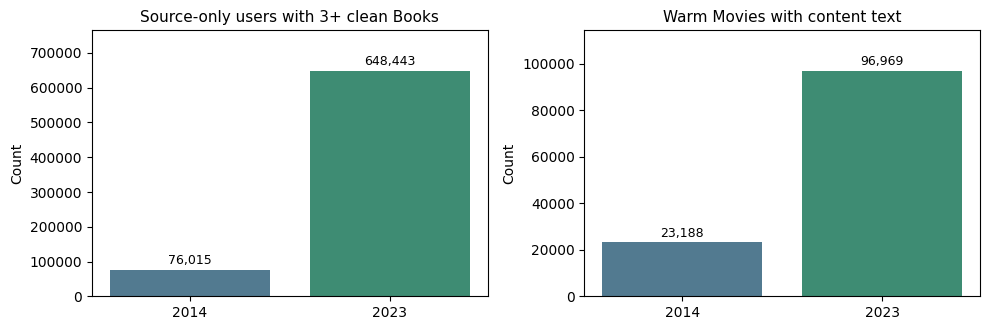

In [7]:
import matplotlib.pyplot as plt
labels = list(prepared)
users = [prepared[r]["coverage"]["populations"]["source_only_training"]["eligible_at_minimum"] for r in labels]
movies = [prepared[r]["coverage"]["warm_movies_with_content"] for r in labels]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, values, title in zip(axes, [users, movies], ["Source-only users with 3+ clean Books", "Warm Movies with content text"]):
    ax.bar(labels, values, color=["#527a90", "#3e8c73"])
    ax.set_title(title, fontsize=11)
    ax.set_ylabel("Count")
    ax.ticklabel_format(axis="y", style="plain")
    for i, value in enumerate(values):
        ax.annotate(f"{value:,}", (i, value), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9)
    ax.margins(y=.18)
fig.tight_layout()
plt.show()

## 7. How to run preprocessing again

The complete implementation is `src/dupgt_cdr/metadata.py`. Use a new output directory to preserve the saved results. The local source snapshots avoid another full download.

```bash
.venv/bin/python -m dupgt_cdr metadata-prepare --dataset 2023 --size full \
  --book-metadata data/metadata/amazon2023/raw_selection/books_source.jsonl.gz \
  --movie-metadata data/metadata/amazon2023/raw_selection/movies_source.jsonl.gz \
  --output-dir data/metadata/amazon2023/reclean
```

The original source URLs, revision, checksums and cleaning decisions are saved beside the data.

## 8. What experiment can we claim?

Use the same DUPGT architecture and the saved **2023** domain factors. Compare fresh 2023 bridges with the same real shared-user subset and training budget: ordinary DUPGT, text-derived supervision, LLM supervision and shuffled-label supervision. Choose settings on validation and lock the runs before final test evaluation.

The existing 2014 run is a baseline reproduction with documented protocol differences. A 2014-versus-2023 score difference does not measure an LLM gain. An improvement must come from the matching 2023 comparisons. Sufficient metadata does not guarantee that the LLM labels will help.